# Historical quantitative component gallery
Internal component identifiers 1–6 refer to the earlier layout. For submitted Figures 1–4, open `paper_figures.ipynb`. Scientific inputs and generator identities are retained.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, HTML, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/paper_figures.json').exists())
sys.path.insert(0, str(ROOT/'src'))
from gw import paper_figures as figures
from gw.supporting_reports import checked
import pandas as pd
import ast
def readable(table, name):
    if name == 'fit_parameters':
        table = table[['family', 'parameters', 'nll', 'ks']].copy()
        table['family'] = table['family'].replace({'GeneralizedGamma':'Generalized Gamma'})
        table['parameters'] = table['parameters'].map(lambda value: ', '.join(f'{x:.4g}' for x in ast.literal_eval(value)))
        table.columns = ['Family', 'Parameters', 'NLL ↓', 'KS ↓']
    elif name == 'per_seed_ece':
        table = table[['Method', 'Seed', 'ECE (%)']]
    return table
REDRAW = False
records = figures.catalog(ROOT)
from gw.publication_ui import folded_table, folded_comparison, compact_settings

## Component 1 · Class-invariant directions


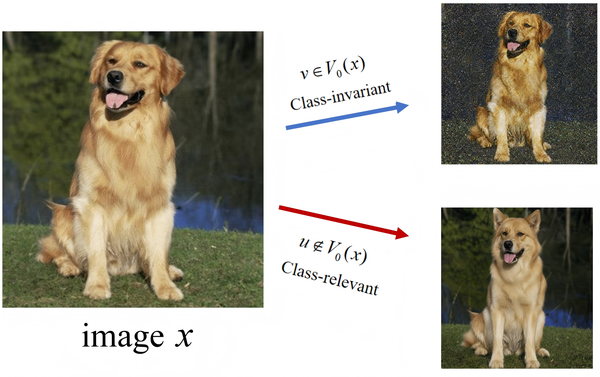
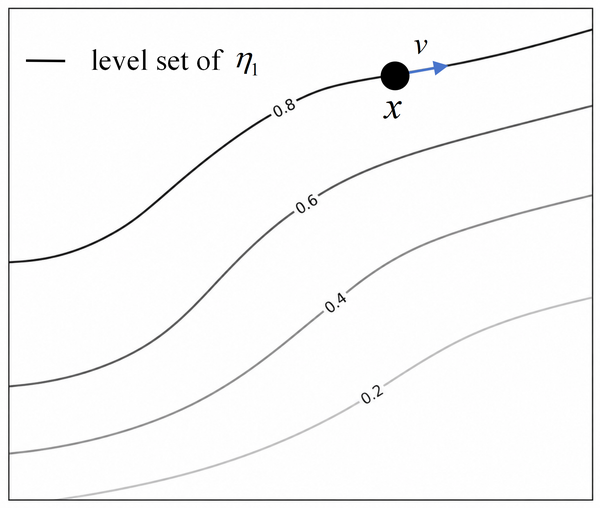
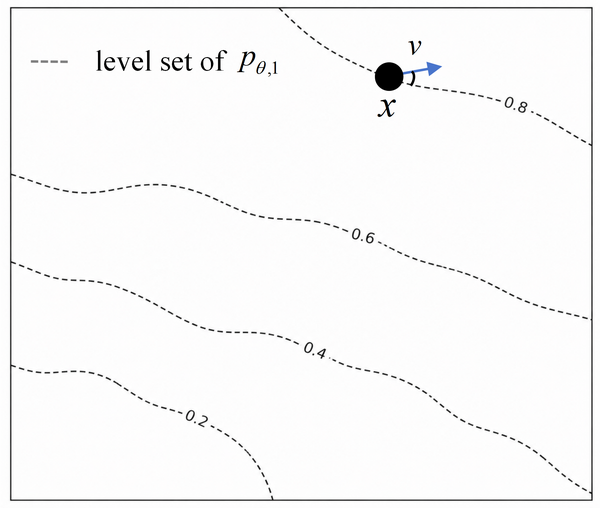

In [2]:
display(HTML(figures.component_html(ROOT, 1, folded=False)))

## Component 2 · Initialization and warm-up

30 paired initializations · validation curves: three seeds, min–max bands · pooled test reliability.

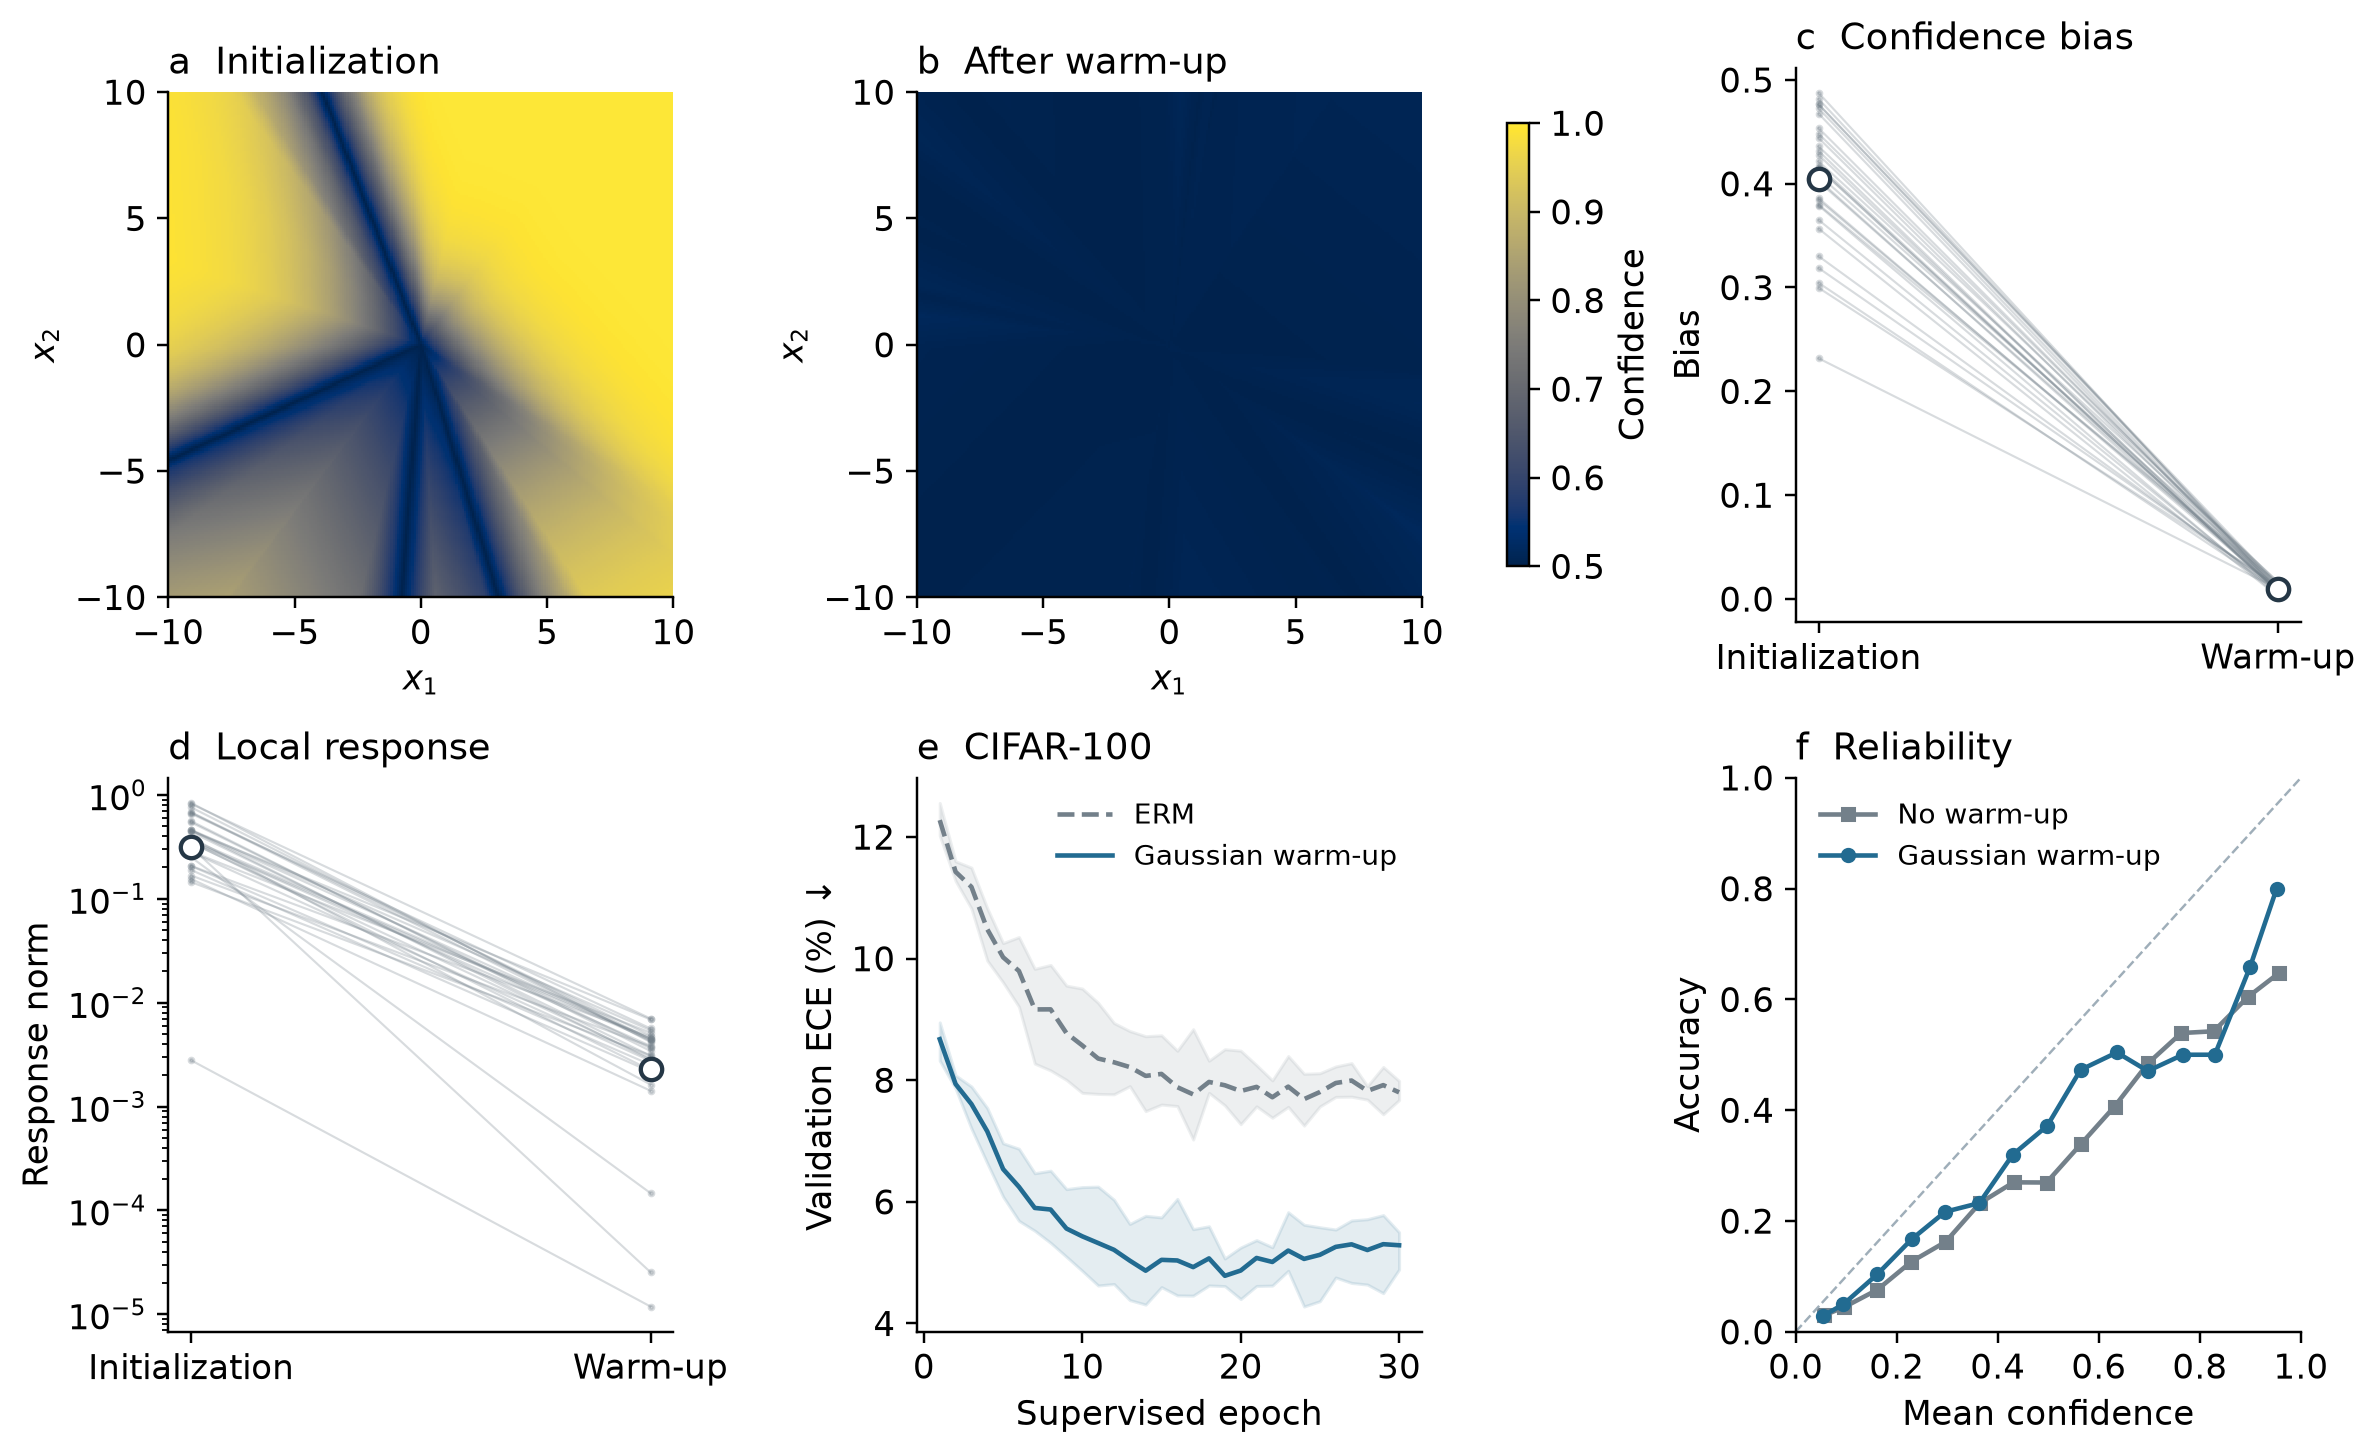

In [3]:
directory = figures.run(ROOT, 2) if REDRAW else ROOT/'results/figures/figure2'
if not REDRAW:
    checked(ROOT, 'results/figures/figure2/figure2.png')
display(Image(filename=str(directory/'figure2.png'), width=1100))


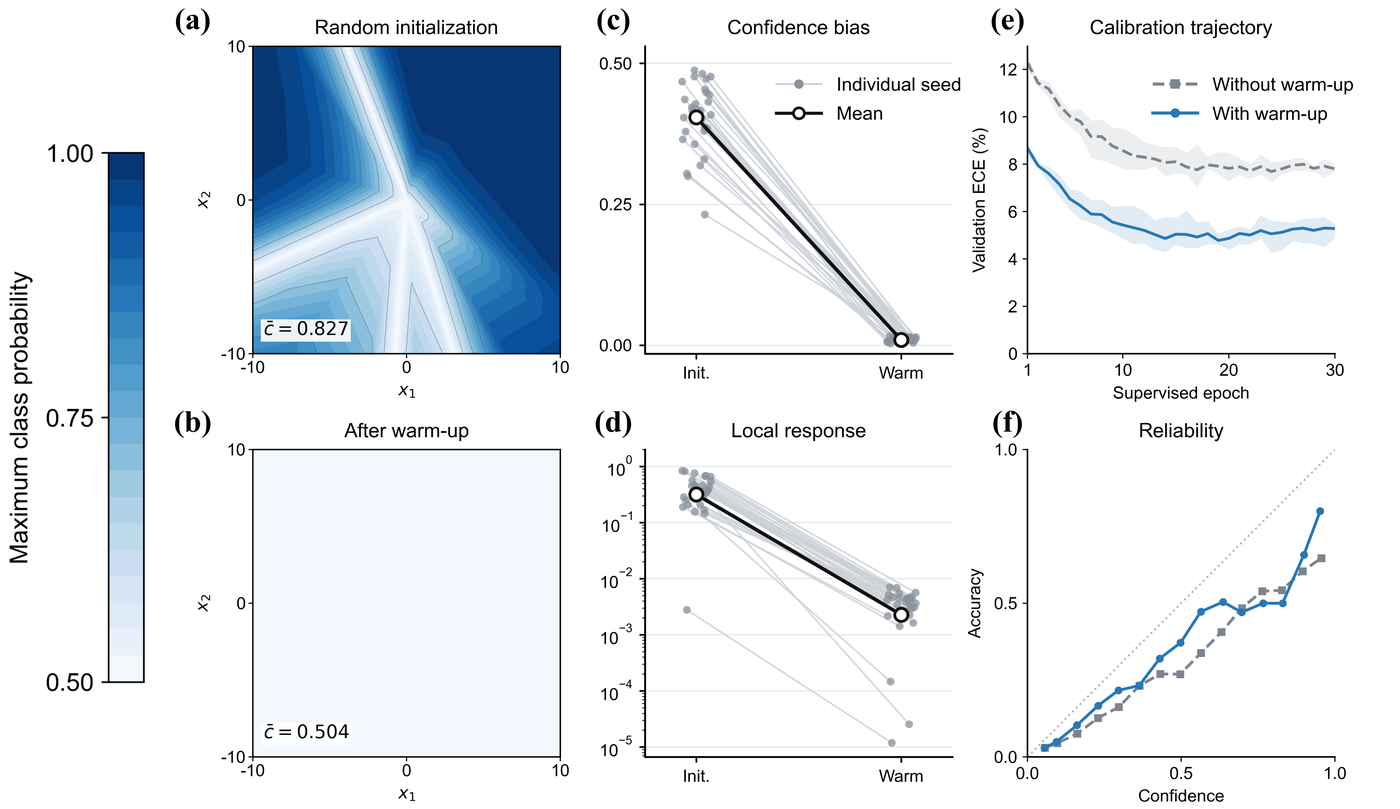

In [4]:
display(HTML(figures.component_html(ROOT, 2, folded=True)))

In [5]:
parts=[]
table=readable(pd.read_csv(directory/'validation_curves.csv', index_col=0), 'validation_curves')
parts.append('<h4>Validation curves</h4><div style="overflow-x:auto">'+table.to_html(index=False, float_format=lambda x: f'{x:.5g}', border=0)+'</div>')
table=readable(pd.read_csv(directory/'reliability_bins.csv', index_col=0), 'reliability_bins')
parts.append('<h4>Reliability bins</h4><div style="overflow-x:auto">'+table.to_html(index=False, float_format=lambda x: f'{x:.5g}', border=0)+'</div>')
display(HTML('<details><summary>Data and settings</summary><p>Toy warm-up uses balanced shuffled hard labels; CIFAR uses random-class hard labels. Heatmaps share the 0.5–1 confidence scale. Local response uses a log axis and geometric mean; empty reliability bins are omitted.</p>'+''.join(parts)+'</details>'))

Method,Epoch,Mean,Low,High
ERM,1,12.276,12.021,12.559
ERM,2,11.427,11.276,11.599
ERM,3,11.179,10.823,11.495
ERM,4,10.482,9.9658,10.827
ERM,5,10.02,9.6073,10.254
ERM,6,9.7951,9.2071,10.353
ERM,7,9.1628,8.2709,9.8308
ERM,8,9.164,8.1586,9.894
ERM,9,8.772,8.0029,9.5538
ERM,10,8.5703,7.7899,9.5056


## Component 3 · Directional coverage

Response panels (c,d) · 100 paired seeds · geometric means and pointwise 95% bootstrap intervals.

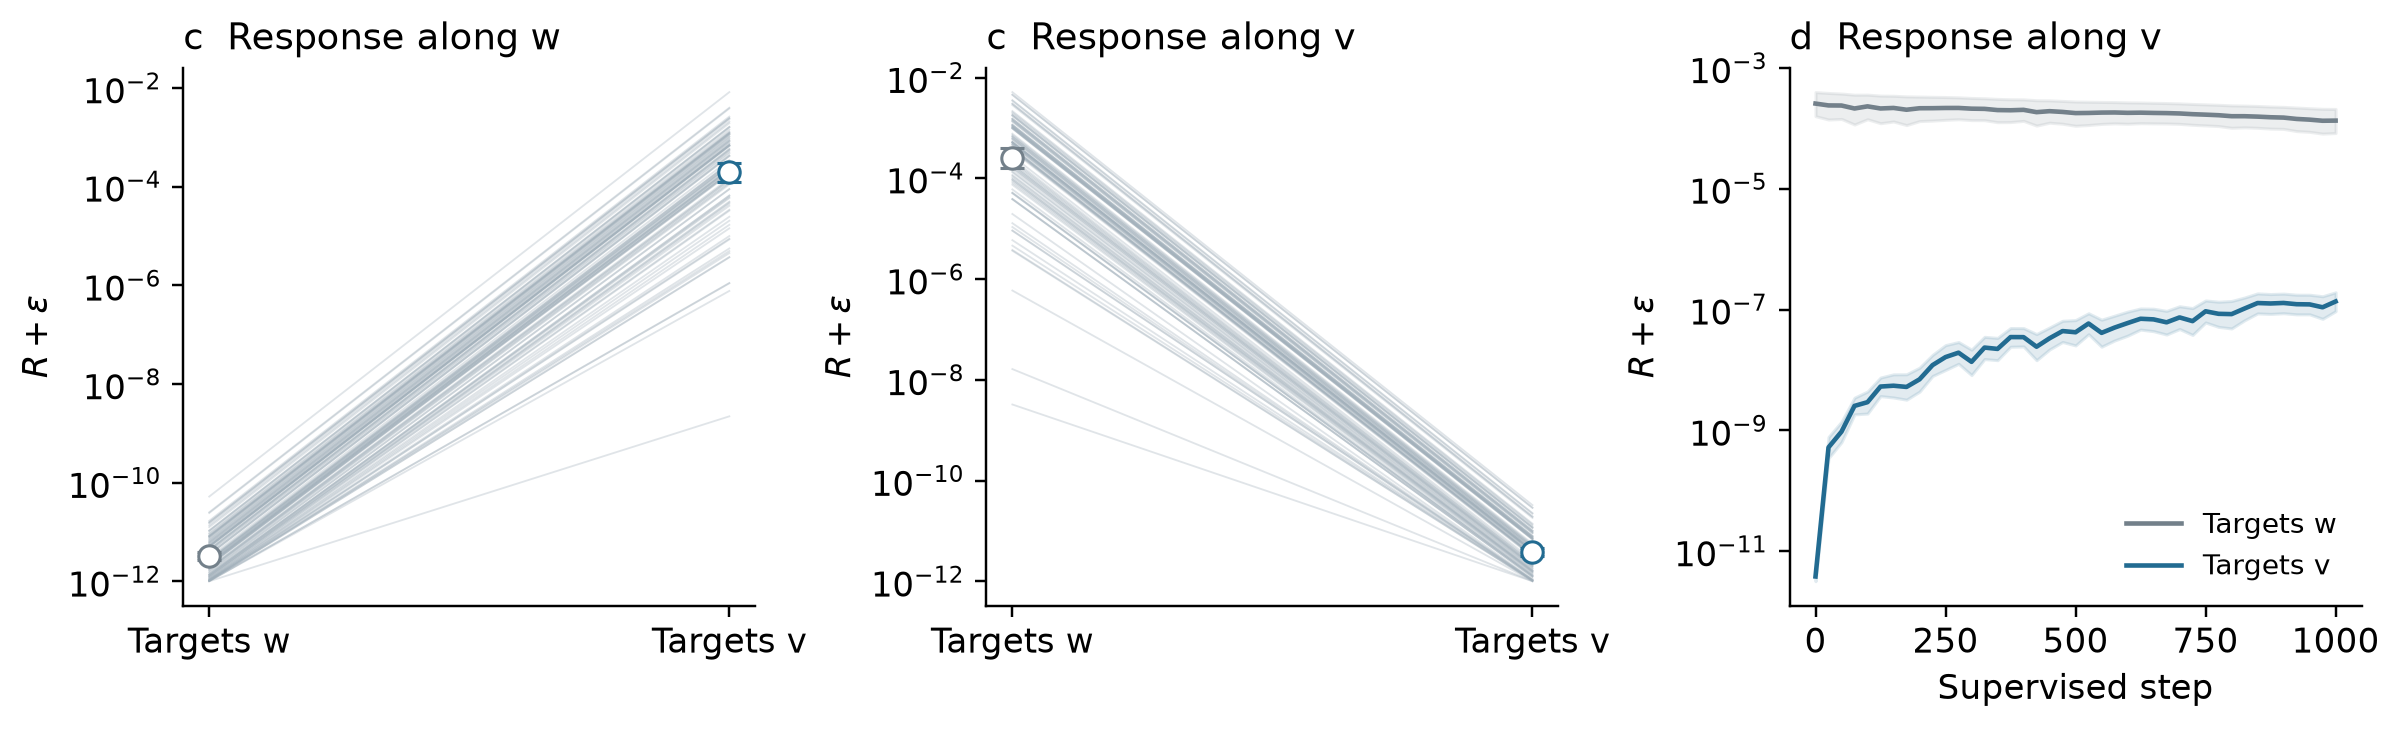

In [6]:
directory = figures.run(ROOT, 3) if REDRAW else ROOT/'results/figures/figure3'
if not REDRAW:
    checked(ROOT, 'results/figures/figure3/figure3.png')
display(Image(filename=str(directory/'figure3.png'), width=1100))


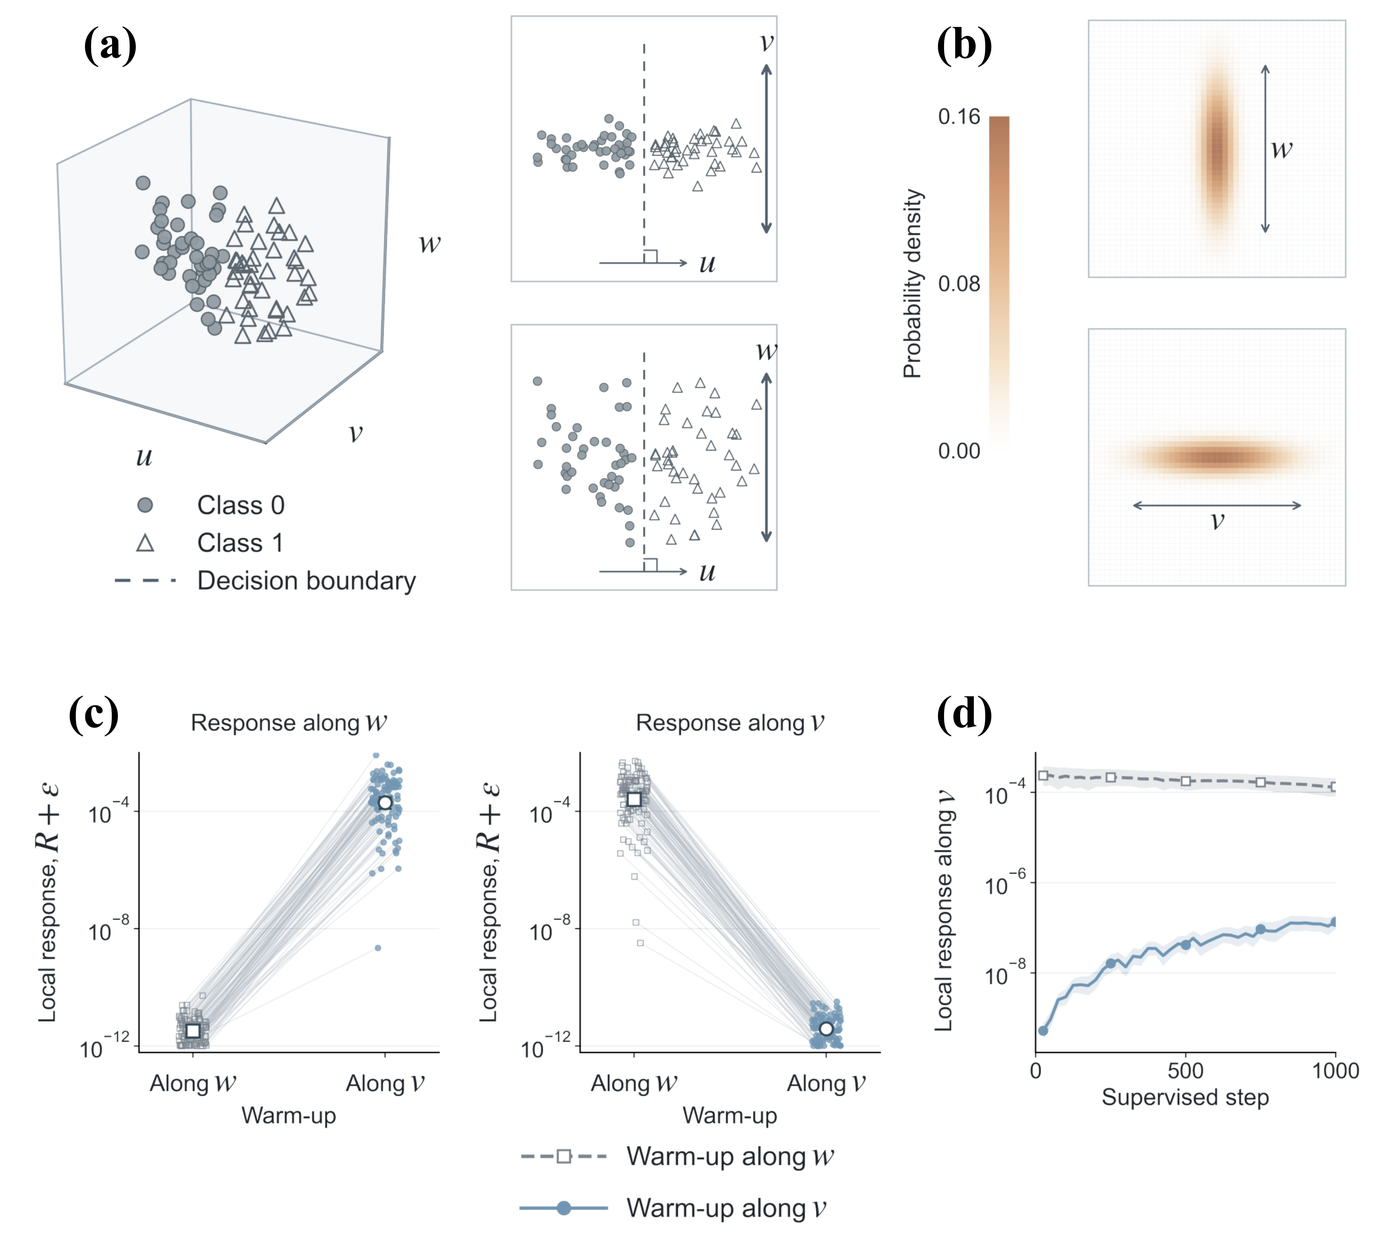

In [7]:
display(HTML(figures.component_html(ROOT, 3, folded=True)))

In [8]:
parts=[]
table=readable(pd.read_csv(directory/'response_intervals.csv', index_col=0), 'response_intervals')
parts.append('<h4>Response intervals</h4><div style="overflow-x:auto">'+table.to_html(index=False, float_format=lambda x: f'{x:.5g}', border=0)+'</div>')
display(HTML('<details><summary>Data and settings</summary><p>Shared resampling indices preserve pairing across methods and times. Bootstrap: 10,000 draws, seed 20261009; log(R + 10⁻¹²). Geometry and density illustrations appear in the manuscript image.</p>'+''.join(parts)+'</details>'))

Phase,Step,Direction,Method,Mean,Low,High,Seeds
supervised,25,u_semantic,targeted_v,0.023043,0.020936,0.025306,100
supervised,25,u_semantic,wrong_w,0.023042,0.020935,0.025304,100
supervised,25,v_weak_nuisance,targeted_v,5.2277e-10,3.4677e-10,7.7823e-10,100
supervised,25,v_weak_nuisance,wrong_w,0.00023848,0.00013934,0.0003835,100
supervised,25,w_strong_nuisance,targeted_v,0.0001516,9.4262e-05,0.00023169,100
supervised,25,w_strong_nuisance,wrong_w,3.3182e-09,2.1798e-09,4.9301e-09,100
supervised,50,u_semantic,targeted_v,0.077976,0.074919,0.081186,100
supervised,50,u_semantic,wrong_w,0.07797,0.074914,0.08118,100
supervised,50,v_weak_nuisance,targeted_v,9.5224e-10,6.3864e-10,1.3939e-09,100
supervised,50,v_weak_nuisance,wrong_w,0.00023754,0.00014239,0.00037481,100


## Component 4 · Optical noise domains

ECE panel · 10 paired seeds · mean and 95% t intervals.

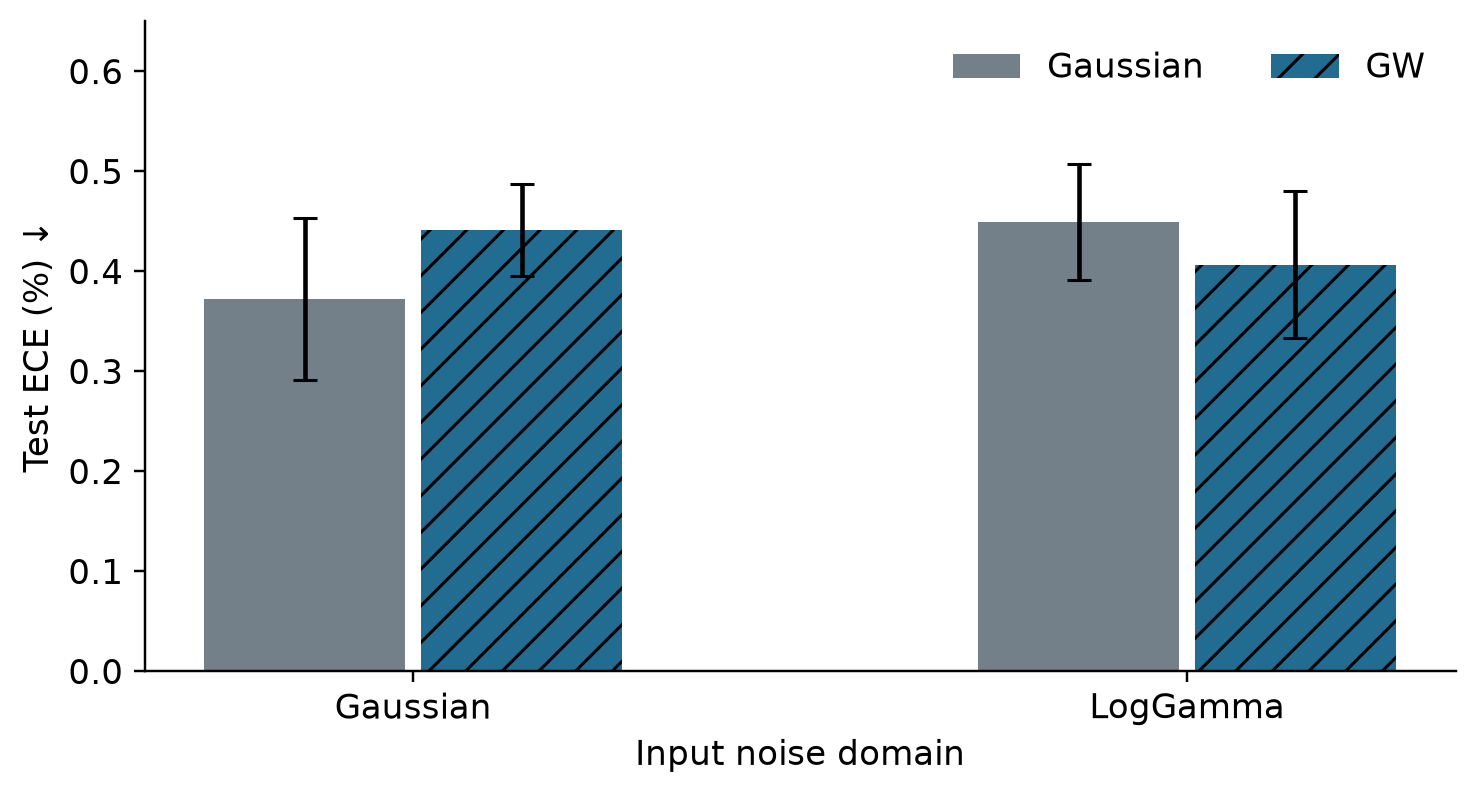

In [9]:
directory = figures.run(ROOT, 4) if REDRAW else ROOT/'results/figures/figure4'
if not REDRAW:
    checked(ROOT, 'results/figures/figure4/figure4.png')
display(Image(filename=str(directory/'figure4.png'), width=1100))


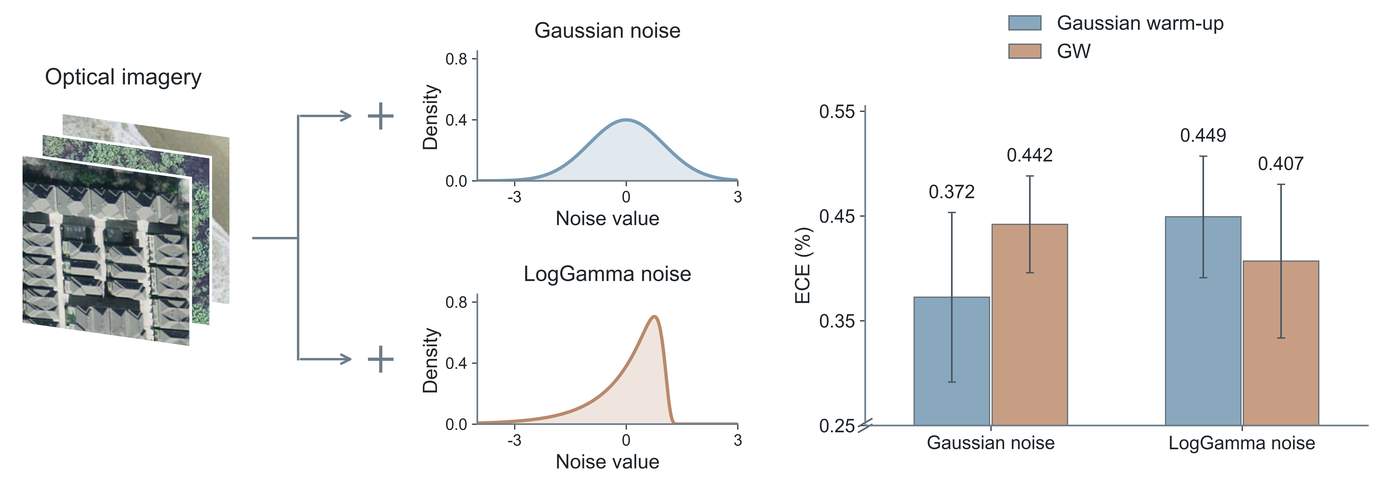

In [10]:
display(HTML(figures.component_html(ROOT, 4, folded=True)))

In [11]:
parts=[]
table=readable(pd.read_csv(directory/'ece_intervals.csv').rename(columns={'Dataset': 'Noise domain'}), 'ece_intervals')
parts.append('<h4>Ece intervals</h4><div style="overflow-x:auto">'+table.to_html(index=False, float_format=lambda x: f'{x:.5g}', border=0)+'</div>')
display(HTML('<details><summary>Data and settings</summary><p>Both methods retain all ten paired seeds in both input-noise domains. Intervals: mean ± t₀.₉₇₅,₉ × SD / √10. The manuscript image also contains illustrative imagery and densities.</p>'+''.join(parts)+'</details>'))

Noise domain,Method,Mean,Low,High,Seeds
Gaussian,GW,0.44169,0.39569,0.48769,10
Gaussian,Gaussian,0.37227,0.29128,0.45327,10
LogGamma,GW,0.40678,0.33364,0.47992,10
LogGamma,Gaussian,0.44914,0.39143,0.50685,10


## Component 5 · GW workflow


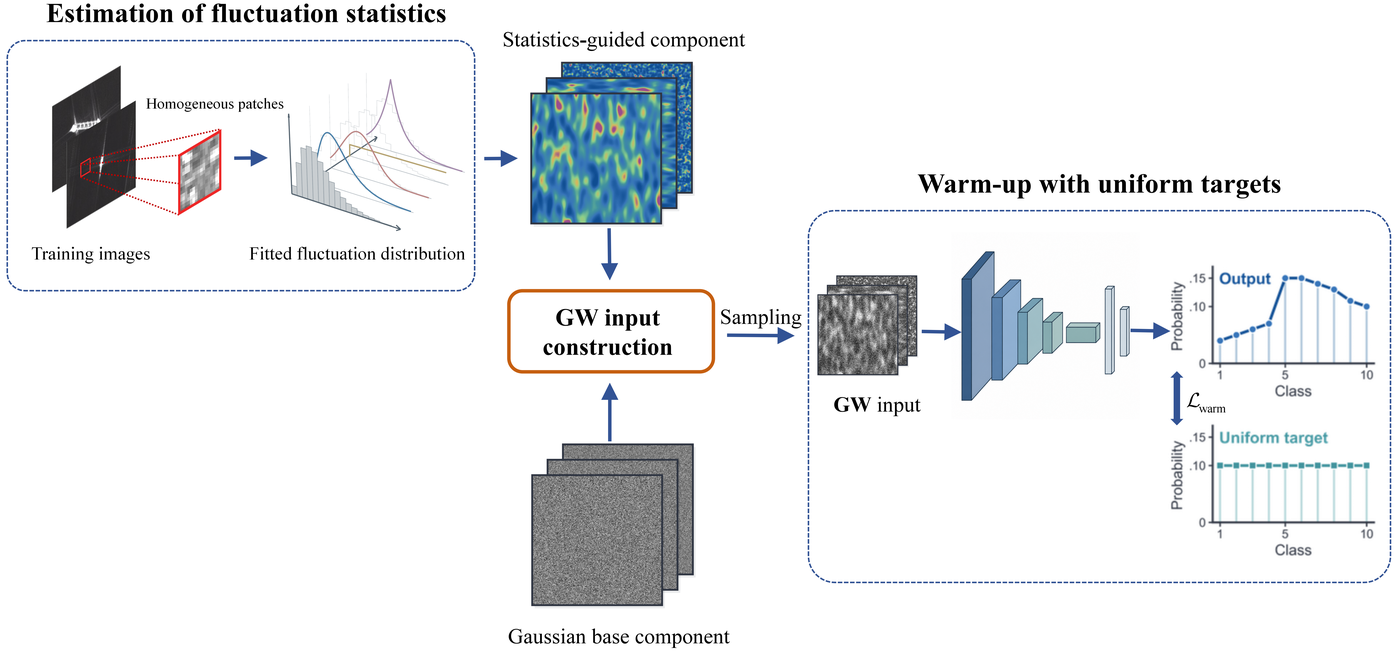

In [12]:
display(HTML(figures.component_html(ROOT, 5, folded=False)))

## Component 6 · Local distribution fits

Selected homogeneous block · distribution fits · five-seed warm-up ECE, mean ± SD.

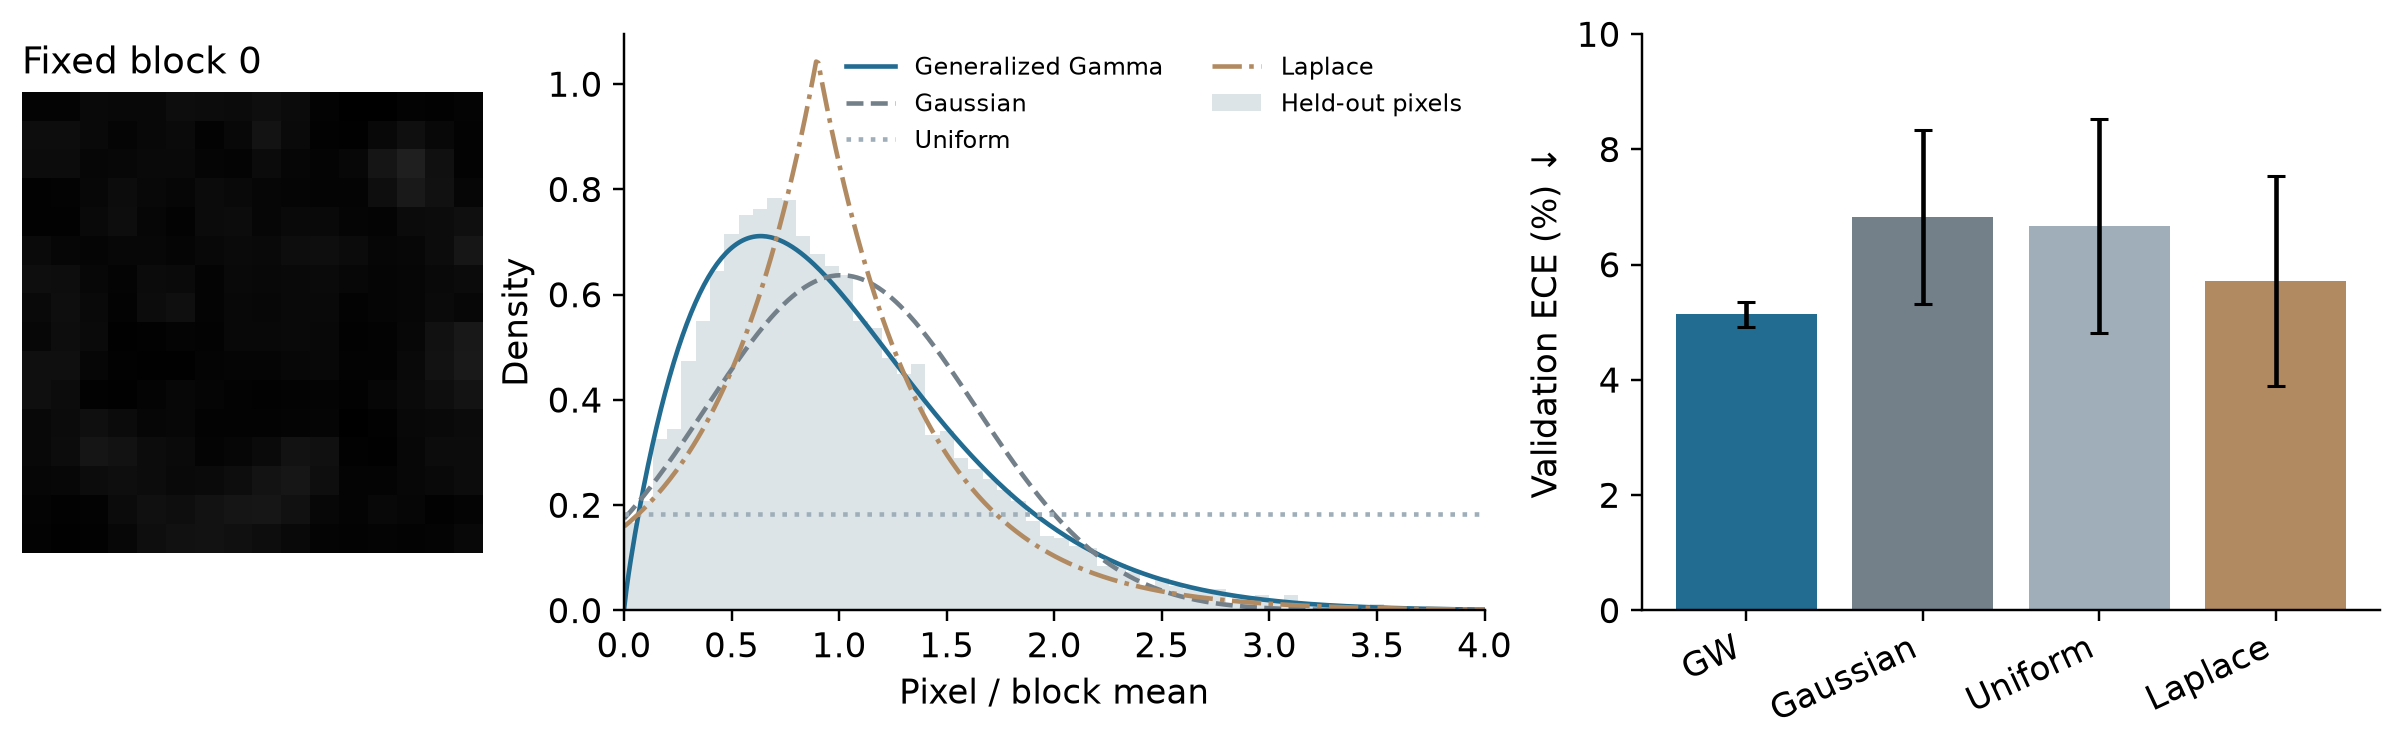

In [13]:
directory = figures.run(ROOT, 6) if REDRAW else ROOT/'results/figures/figure6'
if not REDRAW:
    checked(ROOT, 'results/figures/figure6/figure6.png')
display(Image(filename=str(directory/'figure6.png'), width=1100))


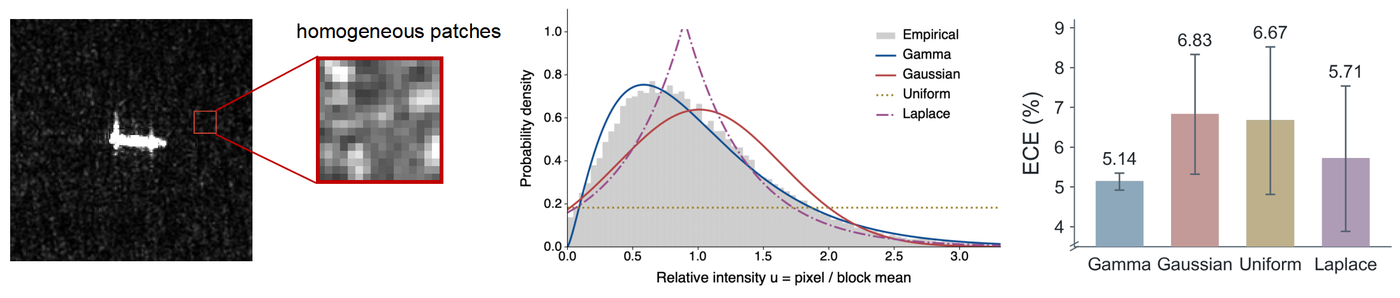

In [14]:
display(HTML(figures.component_html(ROOT, 6, folded=True)))

In [15]:
parts=[]
table=readable(pd.read_csv(directory/'fit_parameters.csv', index_col=0), 'fit_parameters')
parts.append('<h4>Fit parameters</h4><div style="overflow-x:auto">'+table.to_html(index=False, float_format=lambda x: f'{x:.5g}', border=0)+'</div>')
table=readable(pd.read_csv(directory/'per_seed_ece.csv', index_col=0), 'per_seed_ece')
parts.append('<h4>Per seed ece</h4><div style="overflow-x:auto">'+table.to_html(index=False, float_format=lambda x: f'{x:.5g}', border=0)+'</div>')
display(HTML('<details><summary>Data and settings</summary><p>The reconstruction displays one selected homogeneous block; the manuscript crop is available above. Fits use positive pixel/block-mean samples from held-out groups, seed 91501; zeros are excluded and counted. The fitted family is generalized Gamma. Warm-up error bars: sample SD.</p>'+''.join(parts)+'</details>'))

## Regenerate

Set `REDRAW = True` above to regenerate numerical components 2, 3, 4 and 6. The generators use the released predictions and source measurements. Command-line example: `python scripts/render_figures.py --component 4`. Submitted figure numbers 1–4 are handled in `paper_figures.ipynb` and by `--figure`.
